
# TP Patte d'oiseau


##### Étudiants :
CHERIF Enzo, GUIVARCH Ewen
##### Responsable pédagogique :
Vincent HUGEL
##### Formation :
SYSMER 3A, Année académique 2024/2025

### I. Modélisation de la patte d'oiseau

<IPython.core.display.Javascript object>


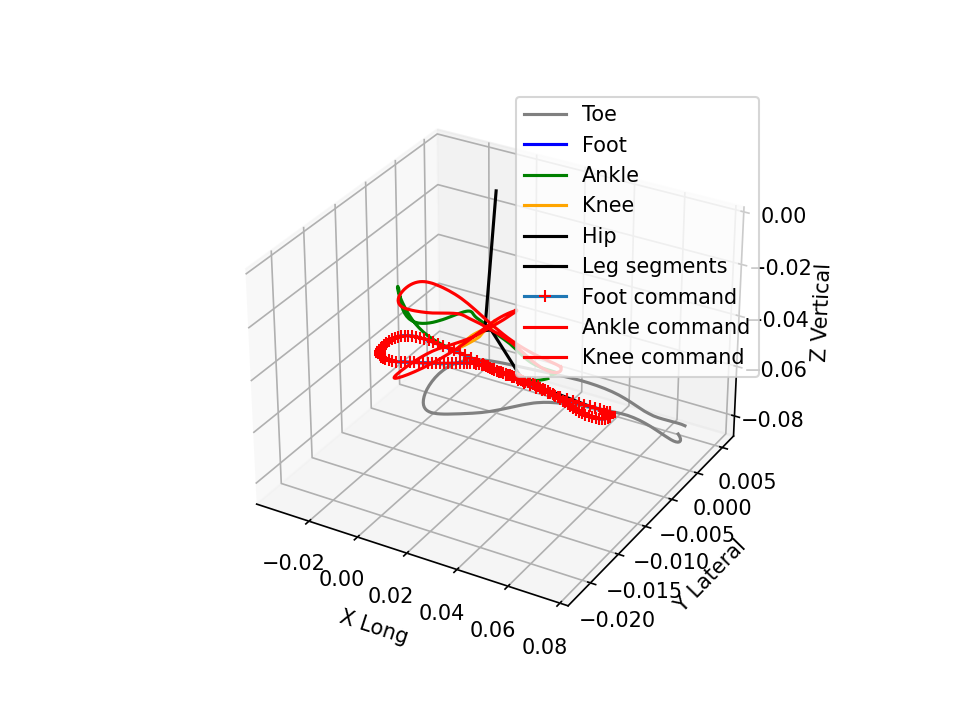

ind_start
35


<IPython.core.display.Javascript object>


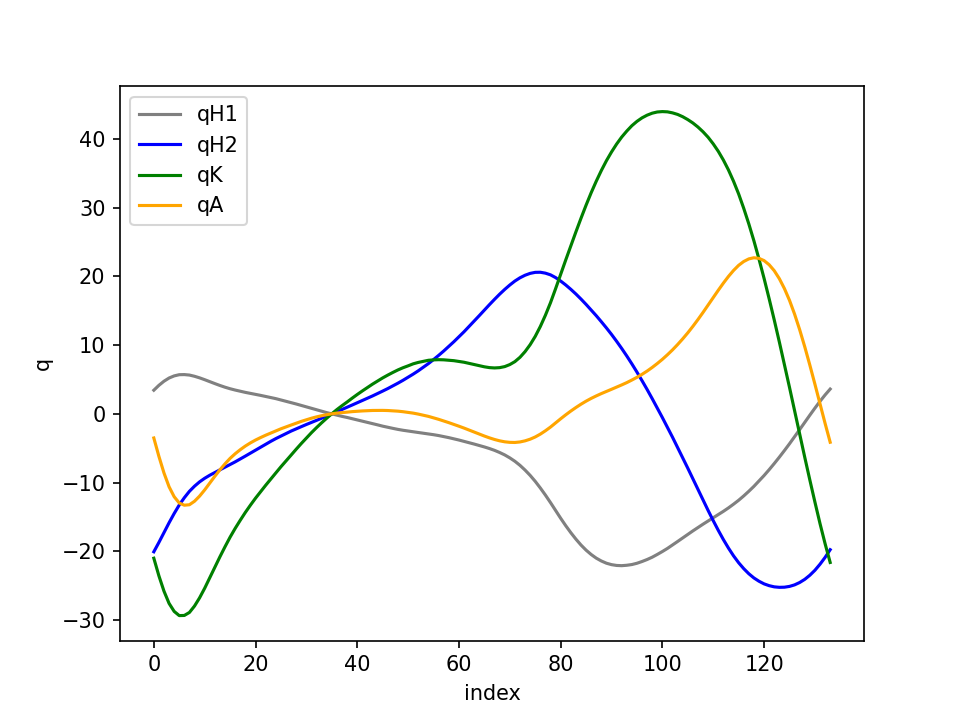

In [8]:
%matplotlib notebook

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d

#!/usr/bin/env python

#############################################################################
# imports
#############################################################################
import numpy as np
import math
import openpyxl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from numpy import linalg as LA

from model import model


#############################################################################
# main function
#############################################################################
if __name__ == '__main__':
	
		######################################################################		
		# read file
		# Define variable to load the dataframe
		dataframe = openpyxl.load_workbook("./fich-from-data-scilab/joints_xyz_average_in_VCp_ref_frame_q12.xlsx")
		#dataframe = openpyxl.load_workbook("./fich-from-data-scilab/joints_xyz_average_in_VCp_ref_frame_mbv.xlsx")
	 
		######################################################################		
		# Define variable to read sheet of data
		ws = dataframe.active
		allCells = np.array([[float(cell.value) for cell in row] for row in ws.iter_rows(2,ws.max_row)])
		xToe = allCells[:,0]
		yToe = allCells[:,1]
		zToe = allCells[:,2]
		xFoot = allCells[:,3]
		yFoot = allCells[:,4]
		zFoot = allCells[:,5]
		xAnkle = allCells[:,6]
		yAnkle = allCells[:,7]
		zAnkle = allCells[:,8]
		xKnee = allCells[:,9]
		yKnee = allCells[:,10]
		zKnee = allCells[:,11]
		xHip = allCells[:,12]
		yHip = allCells[:,13]
		zHip = allCells[:,14]

		######################################################################		
		# plot
		fig = plt.figure()
		ax1 = plt.axes(projection='3d')
		ax1.axis('auto')
		ax1.set_xlabel('X Long')
		ax1.set_ylabel('Y Lateral')
		ax1.set_zlabel('Z Vertical')
		ax1.plot3D(xToe-xHip, yToe-yHip, zToe-zHip, 'gray')
		ax1.plot3D(xFoot-xHip, yFoot-yHip, zFoot-zHip, 'blue')
		ax1.plot3D(xAnkle-xHip, yAnkle-yHip, zAnkle-zHip, 'green')
		ax1.plot3D(xKnee-xHip, yKnee-yHip, zKnee-zHip, 'orange')
		ax1.plot3D(xHip-xHip, yHip-yHip, zHip-zHip, 'black')
		
		######################################################################		
		# plot segments at rest position
		# look for position where projection of knee is in the middle of toe
		min_ = np.max(xFoot) - np.min(xFoot)
		diff = math.fabs(xKnee[0] - (xFoot[0]+xToe[0])/2.0)
		i = 1
		Nsamples = ws.max_row-1
		for i in range (Nsamples):
			if (min_ > diff):
				min_ = diff
				k = i
			diff = math.fabs(xKnee[i] - (xFoot[i]+xToe[i])/2.0)	

		ind_start = k
		print('ind_start')
		print(ind_start)
		seg_x = [0,xKnee[k]-xHip[k],xAnkle[k]-xHip[k],xFoot[k]-xHip[k],xToe[k]-xHip[k]]
		seg_y = [0,yKnee[k]-yHip[k],yAnkle[k]-yHip[k],yFoot[k]-yHip[k],yToe[k]-yHip[k]]
		seg_z = [0,zKnee[k]-zHip[k],zAnkle[k]-zHip[k],zFoot[k]-zHip[k],zToe[k]-zHip[k]]
		ax1.plot3D(seg_x, seg_y, seg_z, 'black')
		
		######################################################################			
		# define arrays for hip, knee, ankle and foot points relative to rest position
		H = np.array([xHip[ind_start],yHip[ind_start],zHip[ind_start]])
		K = np.array([xKnee[ind_start],yKnee[ind_start],zKnee[ind_start]])
		A = np.array([xAnkle[ind_start],yAnkle[ind_start],zAnkle[ind_start]])
		F = np.array([xFoot[ind_start],yFoot[ind_start],zFoot[ind_start]])
		T = np.array([xToe[ind_start],yToe[ind_start],zToe[ind_start]])
		points = np.array([H,K,A,F,T])

        ######################################################################		
		# define orientation angles of inclined hip joint (2nd actuated joint at hip) 
		# to be optimized
		#ang_hip_incl = np.array([116,55])
		ang_hip_incl = np.array([90,90])

		# define orientation angles of inclined ankle joint (4th actuated joint after knee joint 		
		# to be optimized
		#ang_ankle = np.array([-93,67])
		ang_ankle = np.array([90,90])
				
		
		######################################################################		
		# creat an instance of the leg model using class "model"
		MyLegLModel = model(points,ang_hip_incl,ang_ankle);
		
		# inits of current angles
		qHipRoll=0
		qHipIncl=0
		qKnee=0
		qAnkle=0
		# inits of arrays for the angles over the trajectory
		qH1 = [0 for j in range(Nsamples)]
		qH2 = [0 for j in range(Nsamples)]
		qK = [0 for j in range(Nsamples)]
		qA = [0 for j in range(Nsamples)]
		dF = [0 for j in range(Nsamples)]
		Kq = [[0 for j in range(3)] for i in range(Nsamples)]
		Aq= [[0 for j in range(3)] for i in range(Nsamples)]
		Fq = [[0 for j in range(3)] for i in range(Nsamples)]
		
		# inits of initial points at the beginning of the trajectory
		# Be careful, start at index chosen for the reference of the model
		K0 = np.array([xKnee[ind_start]-xHip[ind_start],yKnee[ind_start]-yHip[ind_start],zKnee[ind_start]-zHip[ind_start]])
		A0 = np.array([xAnkle[ind_start]-xHip[ind_start],yAnkle[ind_start]-yHip[ind_start],zAnkle[ind_start]-zHip[ind_start]])
		F0 = np.array([xFoot[ind_start]-xHip[ind_start],yFoot[ind_start]-yHip[ind_start],zFoot[ind_start]-zHip[ind_start]])
		# first variation of foot coordinates
		deltaFoot = np.array([xFoot[ind_start+1]-xFoot[ind_start],yFoot[ind_start+1]-yFoot[ind_start],zFoot[ind_start+1]-zFoot[ind_start]])


		# call calc of direct geometric model
		K,A,F = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)
		# call cal of Jacobian matrices (knee, ankle and foot)
		JK,JA,JF = MyLegLModel.calc_JacobianKneeAnkleFoot(qHipRoll,qHipIncl,qKnee,qAnkle)
		# calc pseudo-inverse for inverse kinematic model
		Jp = LA.pinv(JF)
		# calculate variations of angles for joint control
		Dq = np.dot(Jp,deltaFoot)
		# calculate Z vector to adjust the commands for joint control (reduce the ampltiude w.r.t. initial joint angles)
		MaddZ = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]]) - np.dot(Jp,JF)
		Z = np.dot(MaddZ,np.array([qHipRoll,qHipIncl,qKnee,qAnkle]))  
		# update joint commands with Z
		nu = 1.0		
		qHipRoll = Dq[0] - nu * Z[0]
		qHipIncl = Dq[1] - nu * Z[1]
		qKnee = Dq[2] - nu * Z[2]
		qAnkle = Dq[3] - nu * Z[3]		
	
		# update arrays of current points, knee, ankle and foot by using the DGM with joint commands
		KCurrent,ACurrent,FootCurrent = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)			
		Kq[ind_start] = K0.tolist()	
		Aq[ind_start] = A0.tolist()
		Fq[ind_start] = F0.tolist()
		Kq[ind_start+1] = np.squeeze(KCurrent[0:3]).tolist()
		Aq[ind_start+1] = np.squeeze(ACurrent[0:3]).tolist()
		Fq[ind_start+1] = np.squeeze(FootCurrent[0:3]).tolist()
		qH1[ind_start+1] = qHipRoll
		qH2[ind_start+1] = qHipIncl
		qK[ind_start+1] = qKnee
		qA[ind_start+1] = qAnkle
		
		# loop for all foot points 3D trajectory (inputs) and get joint angle commands
		for m in range(2,Nsamples+2):
			i = (m + ind_start) % Nsamples
			
			# update Footnext using np.array
			Footnext = np.array([xFoot[i]-xHip[i],yFoot[i]-yHip[i],zFoot[i]-zHip[i]])
			
			# update deltaFoot using Footnext adn np.array
			deltaFoot = np.array([Footnext[0]-FootCurrent[0],Footnext[1]-FootCurrent[1],Footnext[2]-FootCurrent[2]])
			
			# update Jacobians using model class function
			JK,JA,JF = MyLegLModel.calc_JacobianKneeAnkleFoot(qHipRoll,qHipIncl,qKnee,qAnkle)
			
			# update pseudo-inverse Jp (J+), use LA library
			Jp = LA.pinv(JF)
			
			# update angle variations using delatFoot and Jp (use scalar product of numpy, np.dot)
			Dq = np.dot(Jp,deltaFoot)
			
			# update matrix for additional Z vector, i.e. (I - J+.J), use np.array
			MaddZ = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]]) - np.dot(Jp,JF)
            
			# update Z using Z =  [I - J+.J][qHipRoll,qHipIncl,qKnee,qAnkle]^T, use np.dot and np.array
			Z = np.dot(MaddZ,np.array([qHipRoll,qHipIncl,qKnee,qAnkle]))
			
			# update q using Dq and Z : q = q + Dq - nu.Z
			qHipRoll = qHipRoll + Dq[0] - nu*Z[0]
			qHipIncl = qHipIncl + Dq[1] - nu * Z[1]
			qKnee = qKnee + Dq[2] - nu * Z[2]
			qAnkle = qAnkle + Dq[3] - nu * Z[3]
			
			# update current positions of knee, ankle and foot by using the DGM of the model class
			KCurrent,ACurrent,FootCurrent = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)
			
			# udpate arrays of joint angles
			qH1[i] = qHipRoll
			qH2[i] = qHipIncl
			qK[i] = qKnee
			qA[i] = qAnkle
			Kq[i] = np.squeeze(KCurrent[0:3]).tolist()
			Aq[i] = np.squeeze(ACurrent[0:3]).tolist()
			Fq[i] = np.squeeze(FootCurrent[0:3]).tolist()
			#dF[i] = math.sqrt(deltaFoot[0]**2 + deltaFoot[1]**2 + deltaFoot[2]**2)
			
			
		######################################################################		
		# add plots of results of kinematic control		
		######################################################################		
		ax1.plot3D(np.array(Fq)[:,0],np.array(Fq)[:,1],np.array(Fq)[:,2], mec='red',marker='+')	
		ax1.plot3D(np.array(Aq)[:,0],np.array(Aq)[:,1],np.array(Aq)[:,2], 'red')					
		ax1.plot3D(np.array(Kq)[:,0],np.array(Kq)[:,1],np.array(Kq)[:,2], 'red')
		ax1.legend(['Toe','Foot', 'Ankle','Knee','Hip','Leg segments','Foot command','Ankle command','Knee command'])
		
		fig2 = plt.figure()
		ax2 = plt.axes()
		ax2.set_xlabel('index')
		ax2.set_ylabel('q')
		ax2.plot(180/math.pi*np.array(qH1), 'gray')
		ax2.plot(180/math.pi*np.array(qH2), 'blue')
		ax2.plot(180/math.pi*np.array(qK), 'green')
		ax2.plot(180/math.pi*np.array(qA), 'orange')
		ax2.legend(['qH1', 'qH2','qK','qA'])

		plt.show()	








### II - Optimisation de la trajectoire

<IPython.core.display.Javascript object>


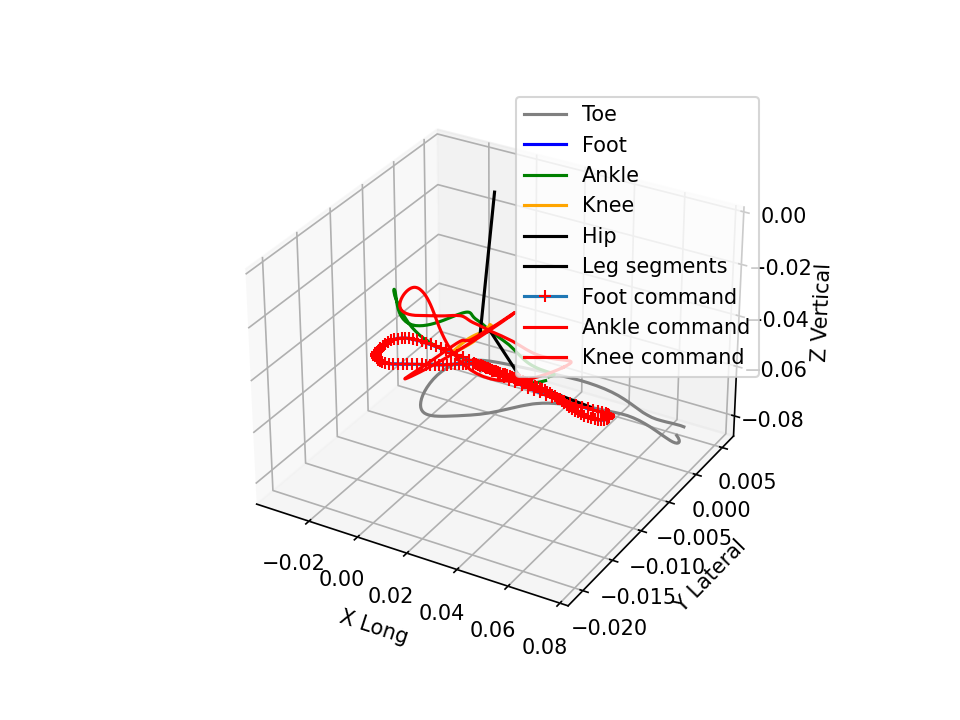

ind_start
35
Voici Xopt
      fun: 0.3781940675503062
 hess_inv: array([[ 2073.07328096,  -762.19423779,   412.24598843, -1185.15094206],
       [ -762.19423779,  8156.14579659, -2404.2948396 ,  1186.136327  ],
       [  412.24598843, -2404.2948396 ,  2917.2063581 ,  -707.32574749],
       [-1185.15094206,  1186.136327  ,  -707.32574749,  9910.84833267]])
      jac: array([1.62422657e-06, 2.90572643e-07, 1.24797225e-06, 4.35113907e-06])
  message: 'Optimization terminated successfully.'
     nfev: 315
      nit: 49
     njev: 63
   status: 0
  success: True
        x: array([140.29600738,  77.2621934 , 116.16948064, 112.68149703])


<IPython.core.display.Javascript object>


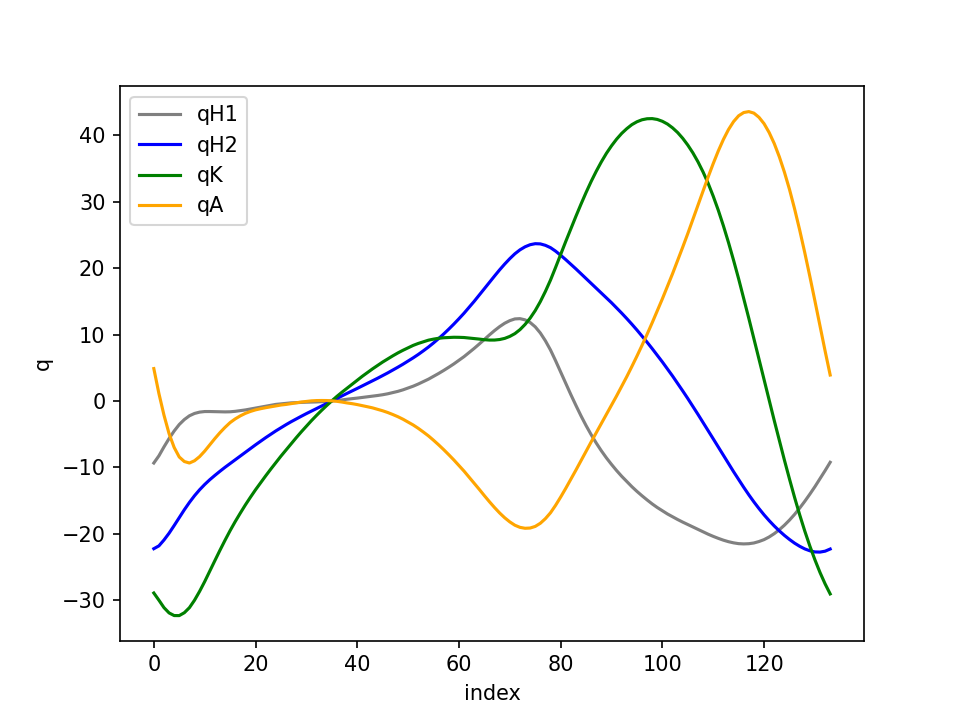

In [13]:
#!/usr/bin/env python

#############################################################################
# imports
#############################################################################
import numpy as np
import math
import openpyxl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from numpy import linalg as LA
from model import model
from scipy.optimize import minimize

#############################################################################
# function cout
#############################################################################
def calcCout (xCt):
	ang_hip = [xCt[0], xCt[1]]
	ang_ankle = [xCt[2], xCt[3]]
	cost = 0
	ct=[0,0,0]
	MyLegLModel.updateDHKKWithOrientationAnglesHipAnkle(ang_hip,ang_ankle)
    
	# inits of current angles
	qHipRoll=0
	qHipIncl=0
	qKnee=0
	qAnkle=0
    
	# inits of arrays for the angles over the trajectory
	qH1 = [0 for j in range(Nsamples)]
	qH2 = [0 for j in range(Nsamples)]
	qK = [0 for j in range(Nsamples)]
	qA = [0 for j in range(Nsamples)]
	dF = [0 for j in range(Nsamples)]
	Kq = [[0 for j in range(3)] for i in range(Nsamples)]
	Aq= [[0 for j in range(3)] for i in range(Nsamples)]
	Fq = [[0 for j in range(3)] for i in range(Nsamples)]
    
	# inits of initial points at the beginning of the trajectory
	# Be careful, start at index chosen for the reference of the model
	K0 = np.array([xKnee[ind_start]-xHip[ind_start],yKnee[ind_start]-yHip[ind_start],zKnee[ind_start]-zHip[ind_start]])
	A0 = np.array([xAnkle[ind_start]-xHip[ind_start],yAnkle[ind_start]-yHip[ind_start],zAnkle[ind_start]-zHip[ind_start]])
	F0 = np.array([xFoot[ind_start]-xHip[ind_start],yFoot[ind_start]-yHip[ind_start],zFoot[ind_start]-zHip[ind_start]])

	# first variation of foot coordinates
	deltaFoot = np.array([xFoot[ind_start+1]-xFoot[ind_start],yFoot[ind_start+1]-yFoot[ind_start],zFoot[ind_start+1]-zFoot[ind_start]])
    
	# call calc of direct geometric model
	K,A,F = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)
    
	# call cal of Jacobian matrices (knee, ankle and foot)
	JK,JA,JF = MyLegLModel.calc_JacobianKneeAnkleFoot(qHipRoll,qHipIncl,qKnee,qAnkle)
    
	# calc pseudo-inverse for inverse kinematic model
	Jp = LA.pinv(JF)
    
	# calculate variations of angles for joint control
	Dq = np.dot(Jp,deltaFoot)
    
	# calculate Z vector to adjust the commands for joint control (reduce the ampltiude w.r.t. initial joint angles)
	MaddZ = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]]) - np.dot(Jp,JF)
	Z = np.dot(MaddZ,np.array([qHipRoll,qHipIncl,qKnee,qAnkle]))  

	# update joint commands with Z
	nu = 1.0
	qHipRoll = Dq[0] - nu * Z[0]
	qHipIncl = Dq[1] - nu * Z[1]
	qKnee = Dq[2] - nu * Z[2]
	qAnkle = Dq[3] - nu * Z[3]
    
	# update arrays of current points, knee, ankle and foot by using the DGM with joint commands
	KCurrent,ACurrent,FootCurrent = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)			
	Kq[ind_start] = K0.tolist()	
	Aq[ind_start] = A0.tolist()
	Fq[ind_start] = F0.tolist()
	Kq[ind_start+1] = np.squeeze(KCurrent[0:3]).tolist()
	Aq[ind_start+1] = np.squeeze(ACurrent[0:3]).tolist()
	Fq[ind_start+1] = np.squeeze(FootCurrent[0:3]).tolist()
	qH1[ind_start+1] = qHipRoll
	qH2[ind_start+1] = qHipIncl
	qK[ind_start+1] = qKnee
	qA[ind_start+1] = qAnkle
    
	# loop for all foot points 3D trajectory (inputs) and get joint angle commands
	for m in range(2,Nsamples+2):
		i = (m + ind_start) % Nsamples
        
		# update Footnext using np.array
		Footnext = np.array([xFoot[i]-xHip[i],yFoot[i]-yHip[i],zFoot[i]-zHip[i]])
        
		# update deltaFoot using Footnext adn np.array
		deltaFoot = np.array([Footnext[0]-FootCurrent[0],Footnext[1]-FootCurrent[1],Footnext[2]-FootCurrent[2]])
        
		# update Jacobians using model class function
		JK,JA,JF = MyLegLModel.calc_JacobianKneeAnkleFoot(qHipRoll,qHipIncl,qKnee,qAnkle)
        
		# update pseudo-inverse Jp (J+), use LA library
		Jp = LA.pinv(JF)
        
		# update angle variations using delatFoot and Jp (use scalar product of numpy, np.dot)
		Dq = np.dot(Jp,deltaFoot)
        
		# update matrix for additional Z vector, i.e. (I - J+.J), use np.array
		MaddZ = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]]) - np.dot(Jp,JF)
        
		# update Z using Z =  [I - J+.J][qHipRoll,qHipIncl,qKnee,qAnkle]^T, use np.dot and np.array
		Z = np.dot(MaddZ,np.array([qHipRoll,qHipIncl,qKnee,qAnkle]))
        
		# update q using Dq and Z : q = q + Dq - nu.Z
		qHipRoll = qHipRoll + Dq[0] - nu*Z[0]
		qHipIncl = qHipIncl + Dq[1] - nu * Z[1]
		qKnee = qKnee + Dq[2] - nu * Z[2]
		qAnkle = qAnkle + Dq[3] - nu * Z[3]
        
		# update current positions of knee, ankle and foot by using the DGM of the model class
		KCurrent,ACurrent,FootCurrent = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)
        
		# udpate arrays of joint angles
		qH1[i] = qHipRoll
		qH2[i] = qHipIncl
		qK[i] = qKnee
		qA[i] = qAnkle
        
		Kq[i] = np.squeeze(KCurrent[0:3]).tolist()
		Aq[i] = np.squeeze(ACurrent[0:3]).tolist()
		Fq[i] = np.squeeze(FootCurrent[0:3]).tolist()

        
		ct[0] = (xAnkle[i]-xHip[i]-ACurrent[0])**2
		ct[1] = (yAnkle[i]-yHip[i]-ACurrent[1])**2
		ct[2] = (zAnkle[i]-zHip[i]-ACurrent[2])**2    
        
		cost += np.sqrt(ct[0]+ct[1]+ct[2])  
		### RMSE root mean square error
	return cost



#############################################################################
# main function
#############################################################################
if __name__ == '__main__':
	
		######################################################################		
		# read file
		# Define variable to load the dataframe
		dataframe = openpyxl.load_workbook("./fich-from-data-scilab/joints_xyz_average_in_VCp_ref_frame_q12.xlsx")
		#dataframe = openpyxl.load_workbook("./fich-from-data-scilab/joints_xyz_average_in_VCp_ref_frame_mbv.xlsx")
	 
		######################################################################		
		# Define variable to read sheet of data
		ws = dataframe.active
		allCells = np.array([[float(cell.value) for cell in row] for row in ws.iter_rows(2,ws.max_row)])
		xToe = allCells[:,0]
		yToe = allCells[:,1]
		zToe = allCells[:,2]
		xFoot = allCells[:,3]
		yFoot = allCells[:,4]
		zFoot = allCells[:,5]
		xAnkle = allCells[:,6]
		yAnkle = allCells[:,7]
		zAnkle = allCells[:,8]
		xKnee = allCells[:,9]
		yKnee = allCells[:,10]
		zKnee = allCells[:,11]
		xHip = allCells[:,12]
		yHip = allCells[:,13]
		zHip = allCells[:,14]

		######################################################################		
		# plot
		fig = plt.figure()
		ax1 = plt.axes(projection='3d')
		ax1.axis('auto')
		ax1.set_xlabel('X Long')
		ax1.set_ylabel('Y Lateral')
		ax1.set_zlabel('Z Vertical')
		ax1.plot3D(xToe-xHip, yToe-yHip, zToe-zHip, 'gray')
		ax1.plot3D(xFoot-xHip, yFoot-yHip, zFoot-zHip, 'blue')
		ax1.plot3D(xAnkle-xHip, yAnkle-yHip, zAnkle-zHip, 'green')
		ax1.plot3D(xKnee-xHip, yKnee-yHip, zKnee-zHip, 'orange')
		ax1.plot3D(xHip-xHip, yHip-yHip, zHip-zHip, 'black')
		
		######################################################################		
		# plot segments at rest position
		# look for position where projection of knee is in the middle of toe
		min_ = np.max(xFoot) - np.min(xFoot)
		diff = math.fabs(xKnee[0] - (xFoot[0]+xToe[0])/2.0)
		i = 1
		Nsamples = ws.max_row-1
		for i in range (Nsamples):
			if (min_ > diff):
				min_ = diff
				k = i
			diff = math.fabs(xKnee[i] - (xFoot[i]+xToe[i])/2.0)	

		ind_start = k
		print('ind_start')
		print(ind_start)
		seg_x = [0,xKnee[k]-xHip[k],xAnkle[k]-xHip[k],xFoot[k]-xHip[k],xToe[k]-xHip[k]]
		seg_y = [0,yKnee[k]-yHip[k],yAnkle[k]-yHip[k],yFoot[k]-yHip[k],yToe[k]-yHip[k]]
		seg_z = [0,zKnee[k]-zHip[k],zAnkle[k]-zHip[k],zFoot[k]-zHip[k],zToe[k]-zHip[k]]
		
		ax1.plot3D(seg_x, seg_y, seg_z, 'black')
		
		######################################################################			
		# define arrays for hip, knee, ankle and foot points relative to rest position
		H = np.array([xHip[ind_start],yHip[ind_start],zHip[ind_start]])
		K = np.array([xKnee[ind_start],yKnee[ind_start],zKnee[ind_start]])
		A = np.array([xAnkle[ind_start],yAnkle[ind_start],zAnkle[ind_start]])
		F = np.array([xFoot[ind_start],yFoot[ind_start],zFoot[ind_start]])
		T = np.array([xToe[ind_start],yToe[ind_start],zToe[ind_start]])
		points = np.array([H,K,A,F,T])

		######################################################################		
		# define orientation angles of inclined hip joint (2nd actuated joint at hip) 
		# to be optimized
		#ang_hip_incl = np.array([116,55])
		ang_hip_incl = np.array([90,90])

		# define orientation angles of inclined ankle joint (4th actuated joint after knee joint 		
		# to be optimized
		#ang_ankle = np.array([-93,67])
		ang_ankle = np.array([90,90])

		# def para initiaux x
		xPhi = [ang_hip_incl[0],ang_hip_incl[1],ang_ankle[0],ang_ankle[1]]
		xC = np.array(xPhi)
		
		# tableau bounds
		boundsArray = np.array([(50,145),(50,145),(50,145),(50,145)])   #bornes pour chaque para
        
		######################################################################		
		# creat an instance of the leg model using class "model"
		MyLegLModel = model(points,ang_hip_incl,ang_ankle)
		 
		# Calcul du X optimisé
		Xopt = minimize(calcCout, xPhi, bounds=None)   
		print ('Voici Xopt') 
		print (Xopt)
        
		######################################################################		
		# creat an instance of the leg model using class "model" with optimized X
		ang_hipOpt = [Xopt.x[0], Xopt.x[1]]
		ang_ankleOpt = [Xopt.x[2], Xopt.x[3]]
		MyLegLModel.updateDHKKWithOrientationAnglesHipAnkle(ang_hipOpt,ang_ankleOpt)        
             
              
		# inits of current angles
		qHipRoll=0
		qHipIncl=0
		qKnee=0
		qAnkle=0
    
		# inits of arrays for the angles over the trajectory
		qH1 = [0 for j in range(Nsamples)]
		qH2 = [0 for j in range(Nsamples)]
		qK = [0 for j in range(Nsamples)]
		qA = [0 for j in range(Nsamples)]
		dF = [0 for j in range(Nsamples)]
		Kq = [[0 for j in range(3)] for i in range(Nsamples)]
		Aq= [[0 for j in range(3)] for i in range(Nsamples)]
		Fq = [[0 for j in range(3)] for i in range(Nsamples)]
    
		# inits of initial points at the beginning of the trajectory
		# Be careful, start at index chosen for the reference of the model
		K0 = np.array([xKnee[ind_start]-xHip[ind_start],yKnee[ind_start]-yHip[ind_start],zKnee[ind_start]-zHip[ind_start]])
		A0 = np.array([xAnkle[ind_start]-xHip[ind_start],yAnkle[ind_start]-yHip[ind_start],zAnkle[ind_start]-zHip[ind_start]])
		F0 = np.array([xFoot[ind_start]-xHip[ind_start],yFoot[ind_start]-yHip[ind_start],zFoot[ind_start]-zHip[ind_start]])

		# first variation of foot coordinates
		deltaFoot = np.array([xFoot[ind_start+1]-xFoot[ind_start],yFoot[ind_start+1]-yFoot[ind_start],zFoot[ind_start+1]-zFoot[ind_start]])
    
		# call calc of direct geometric model
		K,A,F = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)
    
		# call cal of Jacobian matrices (knee, ankle and foot)
		JK,JA,JF = MyLegLModel.calc_JacobianKneeAnkleFoot(qHipRoll,qHipIncl,qKnee,qAnkle)
    
		# calc pseudo-inverse for inverse kinematic model
		Jp = LA.pinv(JF)
    
		# calculate variations of angles for joint control
		Dq = np.dot(Jp,deltaFoot)
    
		# calculate Z vector to adjust the commands for joint control (reduce the ampltiude w.r.t. initial joint angles)
		MaddZ = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]]) - np.dot(Jp,JF)
		Z = np.dot(MaddZ,np.array([qHipRoll,qHipIncl,qKnee,qAnkle]))  

		# update joint commands with Z
		nu = 1.0
		qHipRoll = Dq[0] - nu * Z[0]
		qHipIncl = Dq[1] - nu * Z[1]
		qKnee = Dq[2] - nu * Z[2]
		qAnkle = Dq[3] - nu * Z[3]
    
		# update arrays of current points, knee, ankle and foot by using the DGM with joint commands
		KCurrent,ACurrent,FootCurrent = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)			
		Kq[ind_start] = K0.tolist()	
		Aq[ind_start] = A0.tolist()
		Fq[ind_start] = F0.tolist()
		Kq[ind_start+1] = np.squeeze(KCurrent[0:3]).tolist()
		Aq[ind_start+1] = np.squeeze(ACurrent[0:3]).tolist()
		Fq[ind_start+1] = np.squeeze(FootCurrent[0:3]).tolist()
		qH1[ind_start+1] = qHipRoll
		qH2[ind_start+1] = qHipIncl
		qK[ind_start+1] = qKnee
		qA[ind_start+1] = qAnkle
    
		# loop for all foot points 3D trajectory (inputs) and get joint angle commands
		for m in range(2,Nsamples+2):
			i = (m + ind_start) % Nsamples
        
			# update Footnext using np.array
			Footnext = np.array([xFoot[i]-xHip[i],yFoot[i]-yHip[i],zFoot[i]-zHip[i]])
        
			# update deltaFoot using Footnext adn np.array
			deltaFoot = np.array([Footnext[0]-FootCurrent[0],Footnext[1]-FootCurrent[1],Footnext[2]-FootCurrent[2]])
        
			# update Jacobians using model class function
			JK,JA,JF = MyLegLModel.calc_JacobianKneeAnkleFoot(qHipRoll,qHipIncl,qKnee,qAnkle)
        
			# update pseudo-inverse Jp (J+), use LA library
			Jp = LA.pinv(JF)
        
			# update angle variations using delatFoot and Jp (use scalar product of numpy, np.dot)
			Dq = np.dot(Jp,deltaFoot)
        
			# update matrix for additional Z vector, i.e. (I - J+.J), use np.array
			MaddZ = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]]) - np.dot(Jp,JF)
        
			# update Z using Z =  [I - J+.J][qHipRoll,qHipIncl,qKnee,qAnkle]^T, use np.dot and np.array
			Z = np.dot(MaddZ,np.array([qHipRoll,qHipIncl,qKnee,qAnkle]))
        
			# update q using Dq and Z : q = q + Dq - nu.Z
			qHipRoll = qHipRoll + Dq[0] - nu*Z[0]
			qHipIncl = qHipIncl + Dq[1] - nu * Z[1]
			qKnee = qKnee + Dq[2] - nu * Z[2]
			qAnkle = qAnkle + Dq[3] - nu * Z[3]
        
			# update current positions of knee, ankle and foot by using the DGM of the model class
			KCurrent,ACurrent,FootCurrent = MyLegLModel.calc_KneeAnkleFootCoord(qHipRoll,qHipIncl,qKnee,qAnkle)
        
			# udpate arrays of joint angles
			qH1[i] = qHipRoll
			qH2[i] = qHipIncl
			qK[i] = qKnee
			qA[i] = qAnkle
        
			Kq[i] = np.squeeze(KCurrent[0:3]).tolist()
			Aq[i] = np.squeeze(ACurrent[0:3]).tolist()
			Fq[i] = np.squeeze(FootCurrent[0:3]).tolist()

        
        
        
		######################################################################		
		# add plots of results of kinematic control		
		######################################################################		
		ax1.plot3D(np.array(Fq)[:,0],np.array(Fq)[:,1],np.array(Fq)[:,2], mec='red',marker='+')	
		ax1.plot3D(np.array(Aq)[:,0],np.array(Aq)[:,1],np.array(Aq)[:,2], 'red')					
		ax1.plot3D(np.array(Kq)[:,0],np.array(Kq)[:,1],np.array(Kq)[:,2], 'red')
		ax1.legend(['Toe','Foot', 'Ankle','Knee','Hip','Leg segments','Foot command','Ankle command','Knee command'])
		
		fig2 = plt.figure()
		ax2 = plt.axes()
		ax2.set_xlabel('index')
		ax2.set_ylabel('q')
		ax2.plot(180/math.pi*np.array(qH1), 'gray')
		ax2.plot(180/math.pi*np.array(qH2), 'blue')
		ax2.plot(180/math.pi*np.array(qK), 'green')
		ax2.plot(180/math.pi*np.array(qA), 'orange')
		ax2.legend(['qH1', 'qH2','qK','qA'])
        
		plt.show()
		
		









